
📊 Overall Status Summary:
status
unknown    582683
Name: count, dtype: int64

📊 Flag Frequency:
missing_metadata_id    0
corpusid_mismatch      0
doi_mismatch           0
missing_embeddings     0
orphan_embeddings      0
doi_missing_sources    0
dtype: int64


/tmp/ipykernel_1700094/1691697455.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="status", palette="Set2")


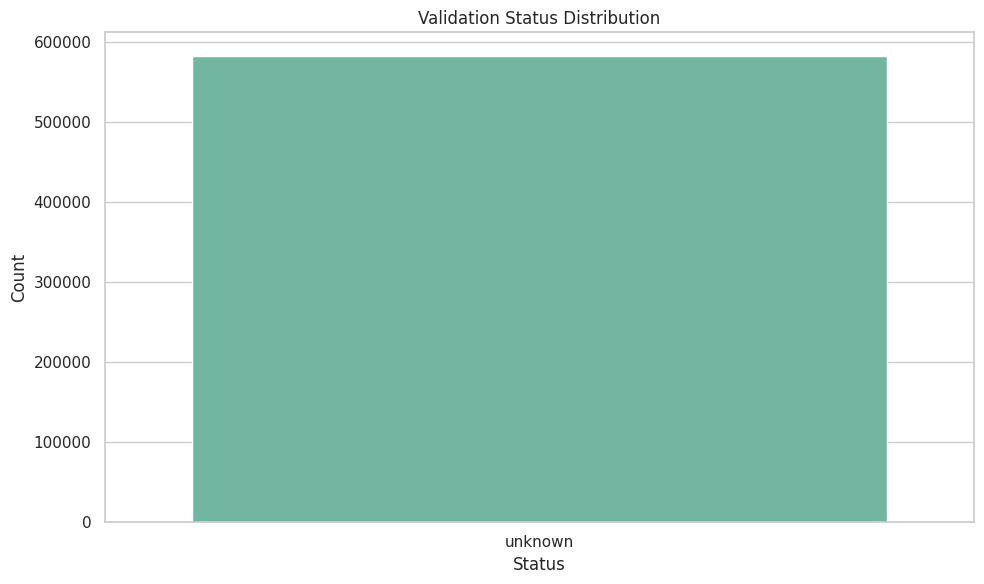

/home/mahmoud/rag/myenv/lib/python3.8/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/home/mahmoud/rag/myenv/lib/python3.8/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


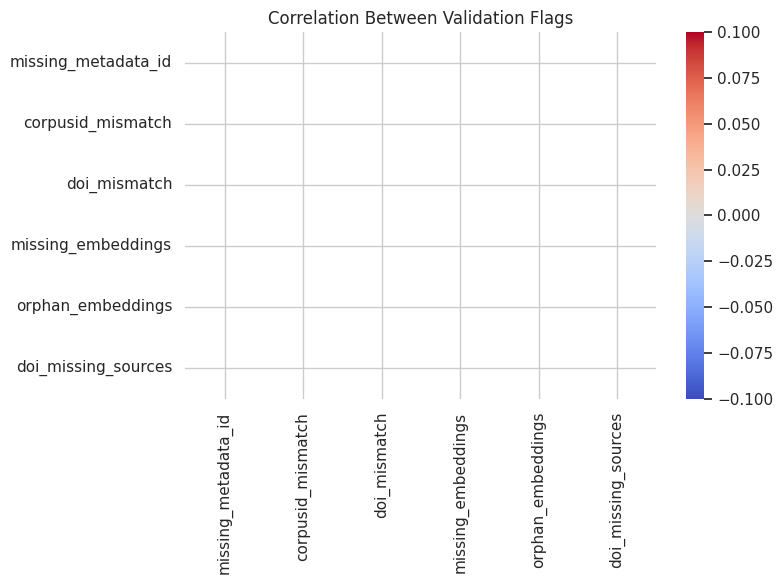

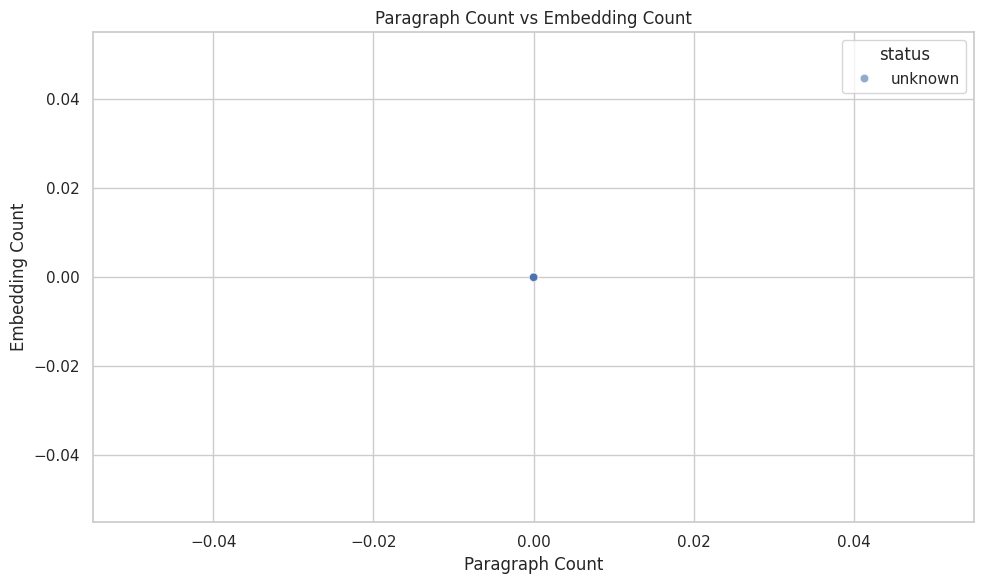

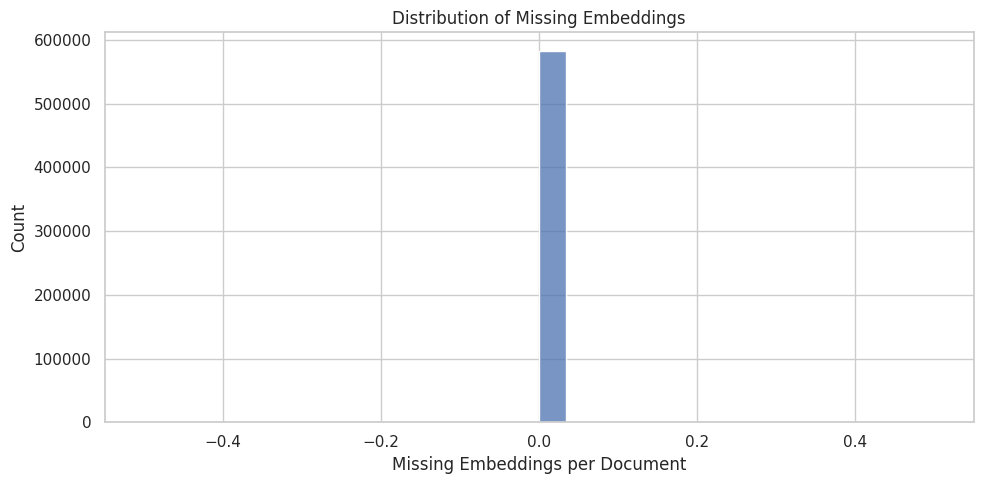

/tmp/ipykernel_1700094/1691697455.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="doi_sources_count", palette="viridis")


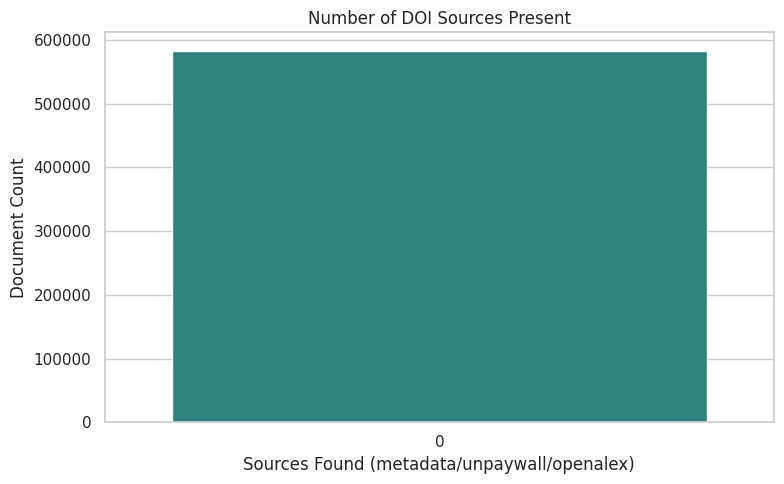

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

# -------------------------
# Configuration
# -------------------------
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
LIMIT = None  # Set to an int to limit documents for testing
EXPORT_CSV = False  # Set to True to export results

# -------------------------
# Connect to MongoDB
# -------------------------
client = MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

# -------------------------
# Query Data
# -------------------------
query = {}
projection = {
    "_id": 1,
    "validation_info.id_validation.status": 1,
    "validation_info.id_validation.flags": 1,
    "validation_info.id_validation.metrics.para_count": 1,
    "validation_info.id_validation.metrics.embed_count": 1,
    "validation_info.id_validation.metrics.doi_sources_present": 1
}

cursor = collection.find(query, projection).limit(LIMIT or 0)
docs = list(cursor)

# -------------------------
# Convert to DataFrame
# -------------------------
records = []
for doc in docs:
    vid = doc.get("validation_info", {}).get("id_validation", {})
    flags = vid.get("flags", {})
    metrics = vid.get("metrics", {})
    doi_present = metrics.get("doi_sources_present", {})

    record = {
        "document_id": doc["_id"],
        "status": vid.get("status", "unknown"),
        "missing_metadata_id": flags.get("missing_metadata_id", False),
        "corpusid_mismatch": flags.get("corpusid_mismatch", False),
        "doi_mismatch": flags.get("doi_mismatch", False),
        "missing_embeddings": flags.get("missing_embeddings", False),
        "orphan_embeddings": flags.get("orphan_embeddings", False),
        "doi_missing_sources": flags.get("doi_missing_sources", False),
        "para_count": metrics.get("para_count", 0),
        "embed_count": metrics.get("embed_count", 0),
        "doi_sources_count": sum(1 for v in doi_present.values() if v)
    }

    records.append(record)

df = pd.DataFrame(records)

if EXPORT_CSV:
    df.to_csv("validation_summary.csv", index=False)

# -------------------------
# Summary Tables
# -------------------------

print("\n📊 Overall Status Summary:")
print(df["status"].value_counts())

print("\n📊 Flag Frequency:")
flag_cols = [
    "missing_metadata_id", "corpusid_mismatch", "doi_mismatch",
    "missing_embeddings", "orphan_embeddings", "doi_missing_sources"
]
print(df[flag_cols].sum().sort_values(ascending=False))

# -------------------------
# Visualization
# -------------------------
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="status", palette="Set2")
plt.title("Validation Status Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Heatmap of flag co-occurrence
plt.figure(figsize=(8, 6))
sns.heatmap(df[flag_cols].astype(int).corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Between Validation Flags")
plt.tight_layout()
plt.show()

# Paragraph vs Embedding Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="para_count", y="embed_count", hue="status", alpha=0.6)
plt.title("Paragraph Count vs Embedding Count")
plt.xlabel("Paragraph Count")
plt.ylabel("Embedding Count")
plt.tight_layout()
plt.show()

# Histogram of missing embeddings
df["missing_embed_count"] = df["para_count"] - df["embed_count"]
plt.figure(figsize=(10, 5))
sns.histplot(df["missing_embed_count"], bins=30, kde=False)
plt.title("Distribution of Missing Embeddings")
plt.xlabel("Missing Embeddings per Document")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# DOI Source Coverage
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="doi_sources_count", palette="viridis")
plt.title("Number of DOI Sources Present")
plt.xlabel("Sources Found (metadata/unpaywall/openalex)")
plt.ylabel("Document Count")
plt.tight_layout()
plt.show()

client.close()
